In [ ]:
%pip install "numexpr==2.8.4" "numpy<2.0.0" --quiet

In [3]:
# import library and setups

import math
import numexpr
import json
import datetime
import sys
import os
import boto3

# Install LangChain and LangGraph
%pip install -U langchain-aws boto3 --quiet
%pip install -U langgraph --quiet

# Setup path
module_path = ".."
sys.path.append(os.path.abspath(module_path))

# Setup Bedrock client
# Amazon Nova 2 Lite is available in us-east-1
bedrock_client = boto3.client('bedrock-runtime', region_name='us-west-2')

# ✅ Amazon Nova 2 Lite — Fast, cost-effective reasoning model
model_id = "us.amazon.nova-2-lite-v1:0"

print("✅ Setup complete")
print(f"   Model : {model_id}")
print(f"   Region: us-west-2")

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
✅ Setup complete
   Model : us.amazon.nova-2-lite-v1:0
   Region: us-west-2


In [4]:
# Import the ChatBedrock class from the langchain_aws module
# This class allows us to interact with the AI model hosted on Amazon Bedrock
from langchain_aws import ChatBedrock

# Create an instance of the ChatBedrock class
# 'model_id' is the ID of the specific AI model you want to use (in this case, Amazon Nova 2 Lite from Amazon Bedrock)
# 'bedrock_client' is the client we created earlier to connect to the AWS Bedrock service
chat_model = ChatBedrock(
    model_id=model_id,  # The model ID we want to interact with (Amazon Nova 2 Lite)
    client=bedrock_client  # The AWS Bedrock client to authenticate and connect to the service
)

# This cell has no visible output — it just creates the chat_model client object.
# We will use chat_model in the next cell to send a request and see a response.
print("No output for this cell. chat_model created successfully — we will see output in the next cell.")

No output for this cell. chat_model created successfully — we will see output in the next cell.


In [5]:
# Invoke the model using the 'invoke' method of the 'chat_model' object

# This sends a query to the Amazon Nova 2 Lite model and receives a response

# In this case, we are asking "What is AWS?" and requesting that the answer be provided in a single sentence
chat_model.invoke("what is AWS? Answer in a single sentence")

AIMessage(content='AWS (Amazon Web Services) is a comprehensive cloud computing platform offered by Amazon, providing a broad range of on-demand services, including computing power, storage, databases, and more, to help businesses build, deploy, and scale applications.', additional_kwargs={}, response_metadata={'ResponseMetadata': {'RequestId': '0fd29962-3b0c-45f8-9015-ff93e5f94e77', 'HTTPStatusCode': 200, 'HTTPHeaders': {'date': 'Tue, 10 Nov 2026 00:58:42 GMT', 'content-type': 'application/json', 'content-length': '453', 'connection': 'keep-alive', 'x-amzn-requestid': '0fd29962-3b0c-45f8-9015-ff93e5f94e77'}, 'RetryAttempts': 0}, 'stopReason': 'end_turn', 'metrics': {'latencyMs': [625]}, 'model_provider': 'bedrock_converse', 'model_name': 'us.amazon.nova-2-lite-v1:0'}, id='lc_run--01a1c2f6-e0ab-7240-b127-72d9a5b1e12d-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 55, 'output_tokens': 50, 'total_tokens': 105, 'input_token_details': {'cache_creation': 0, 'cache

In [6]:
# Importing the 'tool'

# The 'tool' decorator is used to define functions as tools that can be used by LangChain agents
# These tools can be invoked by the agents to perform specific actions like querying a database or performing calculations
from langchain_core.tools import tool

# No output for this cell — it only imports the tool decorator.
# We will use it in the next cells to define tools.
print("No output for this cell. 'tool' decorator imported — we will use it in the next cells.")

No output for this cell. 'tool' decorator imported — we will use it in the next cells.


In [9]:
import csv

# Data to be written to the CSV file (example)
products = [
    {"product_id": "P001", "price": "10.00"},
    {"product_id": "P002", "price": "15.50"},
    {"product_id": "P003", "price": "20.00"}
]

# Open or create the sales.csv file
with open('sales.csv', 'w', newline='') as file:
    # Define the column names
    fieldnames = ['product_id', 'price']

    # Create a CSV dict writer object
    writer = csv.DictWriter(file, fieldnames=fieldnames)

    # Write the header (column names)
    writer.writeheader()

    # Write the product data
    writer.writerows(products)

# Confirm the file is created
print("sales.csv file created successfully!")

sales.csv file created successfully!


In [10]:
# The @tool decorator marks this function as a tool that can be invoked by LangChain agents
@tool
def get_product_price(query: str):
    """
    This function looks up the price of a product from the 'sales.csv' file.

    Args:
    - query (str): The product ID for which the price is being requested.

    Returns:
    - str: The price of the requested product or a message if the product is not found.
    """
    import csv  # Importing the CSV module to read the CSV file

    prices = {}  # Initialize an empty dictionary to store product prices

    # Attempt to open the 'sales.csv' file to read product data
    try:
        file = open('sales.csv', 'r')  # Open the file in read mode
    except Exception as e:
        # If an error occurs while opening the file, return a failure message
        return ("Unable to look up the price for " + query)

    # Read the CSV file and store the data in a dictionary with product_id as the key and price as the value
    reader = csv.DictReader(file)  # Read the CSV as a dictionary
    for row in reader:
        prices[row['product_id']] = row['price']  # Store product ID and price in the dictionary

    file.close()  # Close the file after reading the data

    # Extract the product ID from the user query
    qstr = query.split("\n")[0].strip()  # Take the first line of the query and remove extra spaces

    try:
        # Look up the price in the dictionary and return the result
        return ("Price of product " + qstr + " is " + prices.get(qstr) + "\n")
    except:
        # If the product is not found in the dictionary, return an error message
        return ("Price for product " + qstr + " is not available" + "\n")

# No output for this cell — it only defines the get_product_price tool function.
# We will see it in action later when the agent is invoked.
print("No output for this cell. 'get_product_price' tool defined — we will use it in a later cell.")

No output for this cell. 'get_product_price' tool defined — we will use it in a later cell.


In [11]:
# The @tool decorator marks this function as a tool that can be invoked by LangChain agents

# This function solves mathematical expressions passed as a string, such as "5*4" or "10/2"

@tool
def calculator(expression: str) -> str:
    """
    Use this tool to solve math problems that involve a single-line mathematical expression.
    The expression should use math notation (e.g., "5*4" for multiplication, "5/4" for division).

    Examples:
        - "5*4" for "5 times 4"
        - "5/4" for "5 divided by 4"
    """
    try:
        # The numexpr.evaluate function is used to evaluate the mathematical expression efficiently.
        # It parses and computes the result of the expression in the string.
        return str(
            numexpr.evaluate(
                expression.strip(),  # Remove leading/trailing spaces from the expression
                global_dict={},  # Can be used to pass global math constants (left empty here)
                local_dict={}  # Can be used to pass local variables or constants (left empty here)
            )
        )
    except Exception as e:
        # If the expression cannot be evaluated (e.g., due to invalid syntax), return an error message.
        return "Rethink your approach to this calculation"

# No output for this cell — it only defines the calculator tool function.
# We will see it in action later when the agent is invoked.
print("No output for this cell. 'calculator' tool defined — we will use it in a later cell.")

No output for this cell. 'calculator' tool defined — we will use it in a later cell.


In [12]:
# Create a list of tools that can be used by LangChain agents

# The tools list contains the functions that the agent can call to perform specific actions

tools = [get_product_price, calculator]

# Small confirmation output so we can see this cell ran successfully.
print("Tools list created:", [t.name for t in tools])

Tools list created: ['get_product_price', 'calculator']


In [13]:
# Import necessary classes for handling different types of messages in LangChain
from langchain_core.messages import HumanMessage, SystemMessage, AIMessage, ToolMessage

# Define a function to output the trace information during the execution of the agent
# This function helps in debugging by logging the trace of the agent's reasoning and actions
def output_trace(element: str, trace, node=True):
    global trace_handle  # Declare the trace_handle as global to modify it within the function

    # Check if trace is enabled to print the trace output
    if trace_enabled:
        # Print the current timestamp to the trace file
        print(datetime.datetime.now(), file=trace_handle)

        # Print whether the current element is a node or an edge in the trace
        print(("Node: " if node else "Edge: ") + element, file=trace_handle)

        # If the element is "ask_model_to_reason (entry)", it means the reasoning process is starting,
        # so we print the trace information for each single trace.
        if element == "ask_model_to_reason (entry)":
            for single_trace in trace:
                print(single_trace, file=trace_handle)
        else:
            # Otherwise, print the trace information as it is
            print(trace, file=trace_handle)

        # Print a separator to clearly separate each trace entry in the trace file
        print('----', file=trace_handle)

# Define a function to filter and return only ToolMessage objects from the message list
# ToolMessage objects represent messages exchanged between the agent and external tools
def consolidate_tool_messages(message):
    tool_messages = []  # Initialize an empty list to store ToolMessage objects

    # Loop through the messages and add only ToolMessage objects to the tool_messages list
    for msg in message:
        if isinstance(msg, ToolMessage):  # Check if the message is an instance of ToolMessage
            tool_messages.append(msg)  # Add the ToolMessage to the list

    # Return the list of ToolMessages
    return tool_messages

# No output for this cell — it only defines helper functions.
# We will use output_trace() and consolidate_tool_messages() in the next cells.
print("No output for this cell. 'output_trace' and 'consolidate_tool_messages' functions defined — we will use them in the next cells.")

No output for this cell. 'output_trace' and 'consolidate_tool_messages' functions defined — we will use them in the next cells.


In [14]:
# Import necessary components for building the state graph
from typing import Literal  # Importing Literal to specify possible return types in the function
from langgraph.graph import StateGraph, MessagesState  # Importing StateGraph and MessagesState for graph creation
from langgraph.prebuilt import ToolNode  # Importing ToolNode, a prebuilt component for handling tools in the graph

# ToolNode is a prebuilt component that runs the tool and appends the tool result to the messages
# The 'tools' list contains the available tools (e.g., get_product_price, calculator)
tool_node = ToolNode(tools)

# Bind the tools to the model so that the model knows which tools it can access during execution
model_with_tools = chat_model.bind_tools(tools)

# Define a function for the conditional edge in the agent graph. This function decides the next step based on the messages.
# It checks if the agent's last message includes a tool call. If so, it proceeds to the "tools" node; otherwise, it ends the chain.
def next_step(state: MessagesState) -> Literal["tools", "__end__"]:
    messages = state["messages"]
    last_message = messages[-1]  # Get the last message in the conversation history
    if last_message.tool_calls:
        # If the message includes tool calls, proceed to the "tools" node
        output_trace("next_step: Proceed to tools", last_message, node=False)
        return "tools"
    # Otherwise, end the chain
    output_trace("next_step: Proceed to end", last_message, node=False)
    return "__end__"

# Define the node function that invokes the model to process the messages
# The model will use the tools and reasoning capabilities to generate a response.
def ask_model_to_reason(state: MessagesState):
    messages = state["messages"]
    # Output trace information for debugging
    output_trace("ask_model_to_reason (entry)", consolidate_tool_messages(messages))
    try:
        # Try invoking the model with the available tools and messages
        response = model_with_tools.invoke(messages)
    except Exception as e:
        # If an error occurs, log the exception and return an error message
        output_trace("ask_model_to_reason", messages)
        output_trace("ask_model_to_reason", "Exception: " + str(e))
        return {"messages": [messages.append("Unable to invoke the model")]}  # Append error message to messages
    # Output the response trace and return the generated response
    output_trace("ask_model_to_reason (exit)", response)
    return {"messages": [response]}

# Initialize a StateGraph instance with MessagesState, which represents the state of the conversation
agent_graph = StateGraph(MessagesState)

# Add the nodes to the graph. Each node is associated with a function that will be executed when the node is reached.
agent_graph.add_node("agent", ask_model_to_reason)  # The "agent" node invokes the model to reason
agent_graph.add_node("tools", tool_node)  # The "tools" node invokes the tool(s)

# Define the edges (connections) between the nodes in the graph.
# The agent node is the first to be reached from the entry node.
agent_graph.add_edge("__start__", "agent")

# After the "tools" node is processed, the graph transitions back to the "agent" node
agent_graph.add_edge("tools", "agent")

# The transition from the "agent" node is conditional.
# If the agent's response includes tool calls, the graph moves to the "tools" node; otherwise, it ends.
agent_graph.add_conditional_edges("agent", next_step)

# Compile the graph definition, which prepares it for execution
react_agent = agent_graph.compile()

# No visible output for this cell — it builds and compiles the agent graph.
# We will visualize and use react_agent in the next cells.
print("No output for this cell. Agent graph compiled successfully — we will use react_agent in the next cells.")

No output for this cell. Agent graph compiled successfully — we will use react_agent in the next cells.


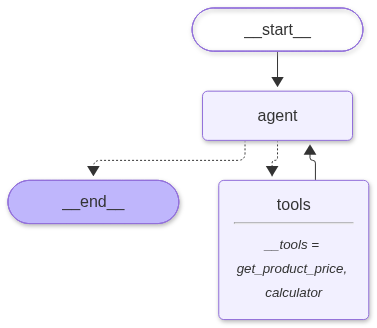

In [15]:
# Import the necessary functions from IPython for displaying images in Jupyter/Colab notebooks
from IPython.display import Image, display

# Try to display the compiled agent graph as a PNG image using Mermaid syntax
try:
    # The get_graph() method generates a graph of the agent's flow, which is then drawn as a Mermaid diagram
    # The draw_mermaid_png() function converts the graph into a PNG image
    display(Image(react_agent.get_graph().draw_mermaid_png()))  # Display the PNG image in the notebook
except Exception as e:
    # If the required dependencies are not available (e.g., for rendering Mermaid diagrams), this block used to silently pass.
    # This step is optional and depends on whether the environment supports Mermaid graph rendering.
    print("No output for this cell. Graph image could not be rendered in this environment:", e)

In [16]:
# Define a function to print the messages from a stream of responses.
# The stream represents a sequence of messages exchanged between the model and other components in LangChain.

def print_stream(stream):
    # Loop through each item in the stream (each item is a message or a set of messages)
    for s in stream:
        # Get the last message in the sequence of messages (assuming 'messages' is a list of message objects)
        message = s["messages"][-1]

        # Check if the last message is a tuple (this can happen if the message contains multiple parts)
        if isinstance(message, tuple):
            # If it is a tuple, print the tuple directly
            print(message)
        else:
            # If the message is not a tuple, call the 'pretty_print' method to format the message nicely
            message.pretty_print()

# No output for this cell — it only defines the print_stream helper function.
# We will use it in the next cells to display the agent's responses.
print("No output for this cell. 'print_stream' function defined — we will use it in a later cell.")

No output for this cell. 'print_stream' function defined — we will use it in a later cell.


In [19]:
# Initialize an empty list to store the questions that will be asked to the agent
questions = []

# Add a question to the list that asks for the total cost of buying a certain number of units of products P002 and P003
questions.append("How much will it cost to buy 3 units of P002 and 5 units of P003?")

# Below are additional questions that are commented out. You can uncomment them to add more questions to the list.
#questions.append("How many units of P010 can I buy with $200?")  # Question asking how many units of P010 can be purchased with $200
#questions.append("Can I buy three units of P003 with $200? If not, how much more should I spend to get three units?")  # Question asking if 3 units of P003 can be bought with $200
#questions.append("Prices have gone up by 8%. How many units of P003 could I have purchased before the price increase with $140? How many can I buy after the price increase? Fractional units are not possible.")  # Question about price increase and its effect on units

# Small confirmation output so we can see this cell ran successfully.
print("Questions list created:", questions)

Questions list created: ['How much will it cost to buy 3 units of P002 and 5 units of P003?']


In [22]:
# Enable tracing for debugging purposes
trace_enabled = True

# Check if trace logging is enabled
if trace_enabled:
    # Create a unique file name for the trace log by appending the current date and time to the string "trace_"
    # This ensures that each trace log has a unique name
    file_name = "trace_" + str(datetime.datetime.now()) + ".txt"

    # Open the trace log file in write mode ('w'). If the file doesn't exist, it will be created.
    # The 'trace_handle' is the file object used to write trace information into the file
    trace_handle = open(file_name, 'w')

# Small confirmation output so we can see this cell ran successfully.
print("No visible output for this cell. Trace logging enabled — trace will be written to:", file_name)

No visible output for this cell. Trace logging enabled — trace will be written to: trace_2026-11-10 02:05:40.315090.txt


In [23]:
# Define the system's message that will guide the model on how to respond to the questions.
# This message instructs the model to think step-by-step and not to make up answers. For math-related queries, it should use the calculator tool.
system_message = "Answer the following questions as best you can. Do not make up an answer. Think step by step. Do not perform intermediate math calculations on your own. Use the calculator tool provided for math calculations."

# Iterate over the list of questions to process each one
for q in questions:
    # Prepare the inputs for the LangChain agent:
    # The input is a list of messages where the system provides the instructions and the user asks the question.
    inputs = {"messages": [("system", system_message), ("user", q)]}

    # Configure additional settings for the agent's execution (such as recursion limit)
    config = {"recursion_limit": 15}

    # Call the agent's stream method to process the input and print the response as it is generated
    # The stream_mode="values" specifies that the agent should output the values of the messages it generates
    print_stream(react_agent.stream(inputs, config, stream_mode="values"))

    # Print a separator to indicate the end of each question's response
    print("\n" + "================================ Answer complete =================================" + "\n")

# If trace logging is enabled, close the trace file to save and finalize the trace data
if trace_enabled:
    trace_handle.close()

================================ Human Message =================================

How much will it cost to buy 3 units of P002 and 5 units of P003?
================================== Ai Message ==================================

[{'type': 'tool_use', 'name': 'get_product_price', 'input': {'query': 'P002'}, 'id': 'tooluse_nOvSiwKNmqAsIXMDsUDxuB'}, {'type': 'tool_use', 'name': 'get_product_price', 'input': {'query': 'P003'}, 'id': 'tooluse_QgY6RJVHnHNGR9yXrHopIp'}]
Tool Calls:
  get_product_price (tooluse_nOvSiwKNmqAsIXMDsUDxuB)
 Call ID: tooluse_nOvSiwKNmqAsIXMDsUDxuB
  Args:
    query: P002
  get_product_price (tooluse_QgY6RJVHnHNGR9yXrHopIp)
 Call ID: tooluse_QgY6RJVHnHNGR9yXrHopIp
  Args:
    query: P003
================================= Tool Message =================================
Name: get_product_price

Price of product P003 is 20.00

================================== Ai Message ==================================

[{'type': 'tool_use', 'name': 'calculator', 'input': {'expressi